# Pseudorandom number generators

*Beyond the exercises — chapter 4 of the scriptum.*

---

Every other notebook calls `random.random()` and trusts it. This notebook asks **what happens behind
that call** and why we may trust it — while a generator the whole world used for years could not be
trusted.

- what a pseudorandom sequence is and why the term is a contradiction
- the **linear congruential generator** (LCG): the simplest thing that works
- **the lattice structure**: why an LCG never gives genuinely independent points
- **RANDU**: the famous IBM generator whose triples lie on 15 planes
- **the Mersenne Twister**: what Python uses and why it is different

Testing the quality (χ², the frequency test, the poker test and company) has its own notebook,
`ch04_tests_of_generators`.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def period(step, seed, limit=10_000_000):
    '''The length of the period: when the state first repeats. Returns None when the limit is not enough.'''
    seen = {}
    x, i = seed, 0
    while i < limit:
        if x in seen:
            return i - seen[x]
        seen[x] = i
        x = step(x)
        i += 1
    return None

## 1. A pseudorandom sequence

"Random numbers from a computer" is a contradiction in terms. A computer is a deterministic machine:
from the same initial state it always produces the same sequence. So what is it that we want?

A sequence that is **deterministic** but **behaves like independent uniform numbers** in every respect
we care about. That is the whole definition — and it is necessarily relative: "in every respect we
care about".

The practical consequences:

- **The state and the seed.** A generator has an internal state; the seed sets it. The same seed ⟹ the
  same numbers. That is not a defect, it is the **reason** the notebooks are reproducible.
- **The period.** The state is finite, so the sequence necessarily becomes cyclic. The period has to
  be much larger than the number of values we consume.
- **The structure.** A long period is a necessary condition, not a sufficient one. A sequence can have
  an enormous period and still carry a hidden dependence — and that is exactly what RANDU fell on.

## 2. The linear congruential generator

The oldest usable construction (Lehmer, 1949):

$$x_{n+1} = (a\,x_n + c) \bmod m, \qquad \gamma_n = \frac{x_n}{m}.$$

Three parameters: the multiplier $a$, the increment $c$, the modulus $m$. The maximum possible period
is $m$ and it is reached only with the right choice (the Hull–Dobell theorem: $c$ coprime with $m$;
$a-1$ divisible by every prime divisor of $m$; and if $m$ is divisible by 4, so must $a-1$ be).

Let us see how sensitive that choice is.

In [2]:
def lcg(a, c, m, seed=1):
    '''A linear congruential generator: returns a function that gives the next γ in [0, 1).'''
    state = seed

    def next_():
        nonlocal state
        state = (a * state + c) % m
        return state / m

    return next_


print(f"{'a':>6} {'c':>5} {'m':>5}   {'period':>8}   {'of maximum':>11}")
for a, c, m in ((137, 187, 256), (136, 187, 256), (125, 0, 256), (5, 1, 256), (17, 3, 256)):
    p = period(lambda x: (a * x + c) % m, 1)
    print(f"{a:>6} {c:>5} {m:>5}   {p:>8}   {p / m:>10.0%}")

     a     c     m     period    of maximum
   137   187   256        256         100%
   136   187   256          1           0%
   125     0   256         64          25%
     5     1   256        256         100%
    17     3   256        256         100%


The same modulus, similar-looking parameters — and the period ranges from the full length to a
handful of steps. Nothing about the generator tells you from the outside which is which; it has to be
computed.

But the period is only the beginning.

## 3. The lattice: what an LCG can never do

Take the pairs of consecutive numbers $(\gamma_n, \gamma_{n+1})$ and draw them as points in a square.
If the numbers were independent, we would get a square evenly sprinkled with points.

We do not. By definition $x_{n+1} = a x_n + c - m\lfloor\cdot\rfloor$, which is a **linear** relation —
and all the points fall onto a family of parallel lines. That is Marsaglia's theorem (1968): pairs
from an LCG lie in the plane on at most $\sqrt{2m}$ lines, triples in space on at most $(6m)^{1/3}$
planes.

The lattice is unavoidable. The only question is whether it is fine enough not to bother us.

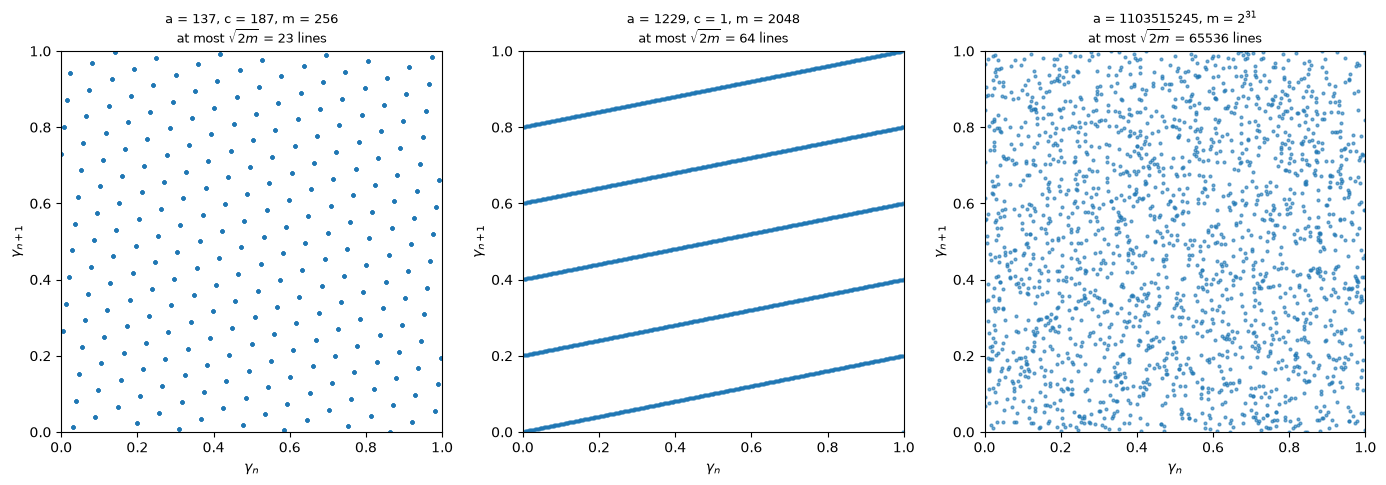

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
M_ = 2048

for ax, (a, c, m, label) in zip(axes, (
        (137, 187, 256, "a = 137, c = 187, m = 256"),
        (1229, 1, 2048, "a = 1229, c = 1, m = 2048"),
        (1103515245, 12345, 2**31, "a = 1103515245, m = $2^{31}$"))):
    gen = lcg(a, c, m)
    xs = [gen() for _ in range(M_)]
    ax.scatter(xs[:-1], xs[1:], s=4, alpha=0.6)
    ax.set_xlabel(r"$\gamma_n$")
    ax.set_ylabel(r"$\gamma_{n+1}$")
    ax.set_title(f"{label}\nat most $\\sqrt{{2m}}$ = {math.sqrt(2 * m):.0f} lines", fontsize=9)
    ax.set_aspect("equal")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()

On the left the lattice is glaring: 256 possible states mean 256 points and a handful of lines. In the
middle it is finer. On the right, with the modulus $2^{31}$, we can no longer make it out in the
picture — there are at most 65 536 lines and the gaps between them are below the resolution of the
image.

**Careful with the conclusion.** On the right the lattice has not disappeared, we just cannot see it.
And it is exactly this invisibility that makes the next demonstration a classic.

## 4. RANDU: what happens when the lattice lands badly

RANDU is a generator shipped by IBM in the 1960s and 1970s and used in thousands of scientific papers:

$$x_{n+1} = 65539\,x_n \bmod 2^{31}.$$

The period is $2^{29}$, the pairs look fine. But $65539 = 2^{16} + 3$, and from that follows

$$x_{n+2} = 6x_{n+1} - 9x_n \pmod{2^{31}},$$

i.e. an exact linear dependence among **three** consecutive numbers. We verify it and then look at
what it does to triples in space.

In [4]:
A_RANDU, M_RANDU = 65539, 2**31

x = 1
states = []
for _ in range(100_000):
    x = (A_RANDU * x) % M_RANDU
    states.append(x)

residues = {(9 * states[i] - 6 * states[i + 1] + states[i + 2]) % M_RANDU for i in range(len(states) - 2)}
print(f"values of (9 x_n - 6 x_(n+1) + x_(n+2)) mod 2^31: {len(residues)}  ->  {residues}")

us = [s / M_RANDU for s in states]
planes = sorted({round(9 * us[i] - 6 * us[i + 1] + us[i + 2]) for i in range(len(us) - 2)})
print(f"so in units of γ, 9γ_n - 6γ_(n+1) + γ_(n+2) = k for integer k: {planes}")
print(f"number of planes: {len(planes)}")

values of (9 x_n - 6 x_(n+1) + x_(n+2)) mod 2^31: 1  ->  {0}
so in units of γ, 9γ_n - 6γ_(n+1) + γ_(n+2) = k for integer k: [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
number of planes: 15


It is an exact equality, not an approximate one: **every** triple of consecutive numbers from RANDU
lies on one of fifteen planes $9\gamma_n - 6\gamma_{n+1} + \gamma_{n+2} = k$, $k = -5,\dots,9$.

Two-dimensional pictures do not reveal it — the dependence is three-dimensional. That is why RANDU was
only found out after years of use.

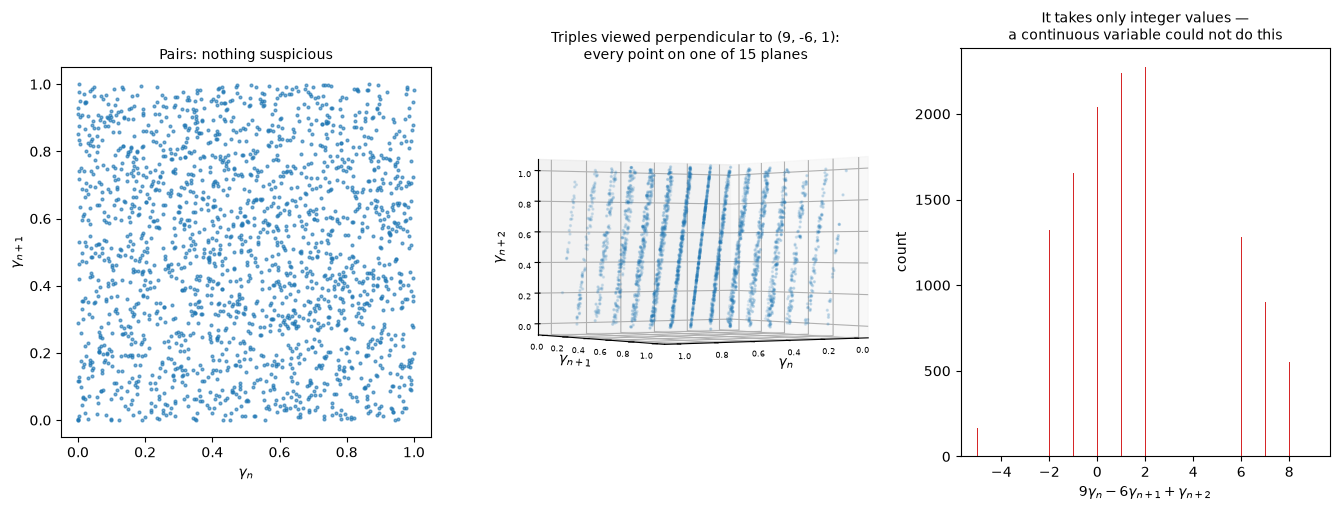

In [5]:
fig = plt.figure(figsize=(13.5, 5.2))

# left: the pairs look impeccable
ax = fig.add_subplot(1, 3, 1)
ax.scatter(us[:2000], us[1:2001], s=4, alpha=0.6)
ax.set_xlabel(r"$\gamma_n$"); ax.set_ylabel(r"$\gamma_{n+1}$")
ax.set_title("Pairs: nothing suspicious", fontsize=10)
ax.set_aspect("equal")

# middle: triples in space, rotated so that the planes are seen edge-on
ax = fig.add_subplot(1, 3, 2, projection="3d")
n3 = 3000
ax.scatter(us[:n3], us[1:n3 + 1], us[2:n3 + 2], s=2, alpha=0.5)
ax.view_init(elev=0, azim=56.31)   # looking perpendicular to the normal (9, -6, 1): the planes show up edge-on
ax.set_xlabel(r"$\gamma_n$", labelpad=-6); ax.set_ylabel(r"$\gamma_{n+1}$", labelpad=-6)
ax.set_zlabel(r"$\gamma_{n+2}$", labelpad=-4)
ax.tick_params(labelsize=6, pad=-2)
ax.set_title("Triples viewed perpendicular to (9, -6, 1):\nevery point on one of 15 planes", fontsize=10)

# right: the same thing as a histogram of the combination, which is integer-valued
ax = fig.add_subplot(1, 3, 3)
combination = [9 * us[i] - 6 * us[i + 1] + us[i + 2] for i in range(20_000)]
ax.hist(combination, bins=600, color="tab:red")
ax.set_xlabel(r"$9\gamma_n - 6\gamma_{n+1} + \gamma_{n+2}$")
ax.set_ylabel("count")
ax.set_title("It takes only integer values —\na continuous variable could not do this", fontsize=10)

plt.tight_layout()
plt.show()

The middle picture is the famous one: from an ordinary angle the cube looks honestly sprinkled with
points, but turned around it shows that it is empty and everything sits on a few planes. The
right-hand picture says the same thing without 3D: a continuous random variable would never take only
integer values.

**The lesson is not "RANDU was bad".** The lesson is that *every* LCG has a lattice structure, only of
differing fineness, and that it shows up in whichever dimension you happen to be testing. A simulation
running in six dimensions can hit a structure that a two-dimensional picture will never show.

## 5. The Mersenne Twister: what Python uses

`random.random()` in Python is the Mersenne Twister MT19937 (Matsumoto and Nishimura, 1998). It is
built differently from an LCG — it works with a state of 19 937 bits, which it mixes with shifts and
XOR operations (a linear feedback shift register over $\mathbb{F}_2$), not with multiplication modulo.

What follows from that:

- **A period of $2^{19937} - 1$.** For comparison, the number of atoms in the universe is around
  $2^{266}$.
- **Equidistribution up to 623 dimensions.** RANDU's triples lay on 15 planes; for MT19937 it is
  guaranteed that even 623-tuples cover the space evenly.
- **It is not cryptographically secure.** From 624 consecutive outputs the whole state can be
  reconstructed and the future computed. For simulations that does not matter, for passwords or keys it
  does — there `secrets` is the right tool.

Let us run the same test that caught RANDU on Python's generator.

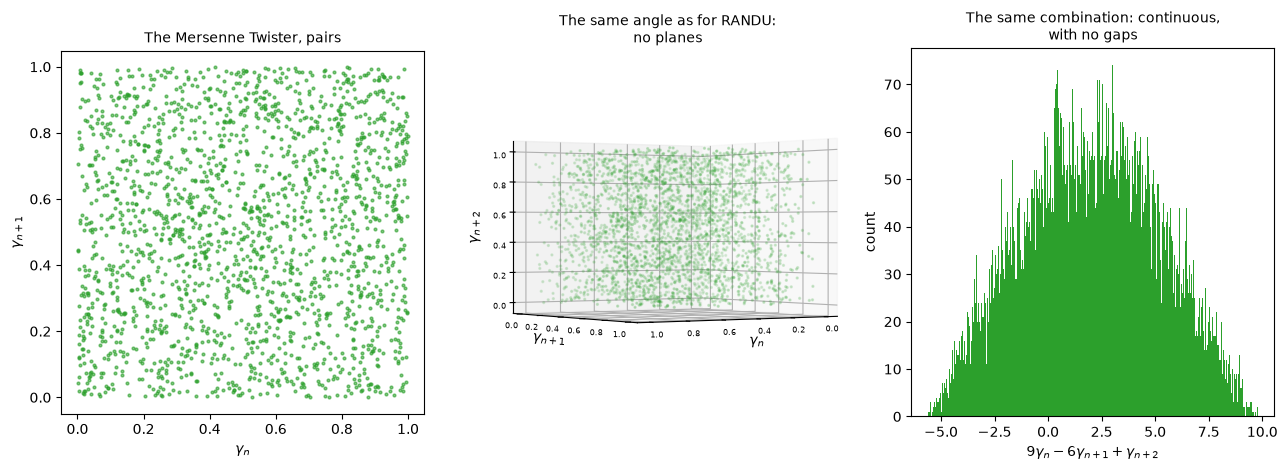

the period of MT19937 = 2^19937 - 1 ≈ 10^6002
state size: 2.43 kB


In [6]:
n3 = 3000
mt = [random.random() for _ in range(n3 + 2)]

fig = plt.figure(figsize=(13, 4.8))

ax = fig.add_subplot(1, 3, 1)
ax.scatter(mt[:2000], mt[1:2001], s=4, alpha=0.6, color="tab:green")
ax.set_xlabel(r"$\gamma_n$"); ax.set_ylabel(r"$\gamma_{n+1}$")
ax.set_title("The Mersenne Twister, pairs", fontsize=10)
ax.set_aspect("equal")

ax = fig.add_subplot(1, 3, 2, projection="3d")
ax.scatter(mt[:n3], mt[1:n3 + 1], mt[2:n3 + 2], s=2, alpha=0.5, color="tab:green")
ax.view_init(elev=0, azim=56.31)   # exactly the same view as for RANDU
ax.set_xlabel(r"$\gamma_n$", labelpad=-6); ax.set_ylabel(r"$\gamma_{n+1}$", labelpad=-6)
ax.set_zlabel(r"$\gamma_{n+2}$", labelpad=-4)
ax.tick_params(labelsize=6, pad=-2)
ax.set_title("The same angle as for RANDU:\nno planes", fontsize=10)

ax = fig.add_subplot(1, 3, 3)
mt2 = [random.random() for _ in range(20_002)]
ax.hist([9 * mt2[i] - 6 * mt2[i + 1] + mt2[i + 2] for i in range(20_000)], bins=600, color="tab:green")
ax.set_xlabel(r"$9\gamma_n - 6\gamma_{n+1} + \gamma_{n+2}$")
ax.set_ylabel("count")
ax.set_title("The same combination: continuous,\nwith no gaps", fontsize=10)

plt.tight_layout()
plt.show()

print(f"the period of MT19937 = 2^19937 - 1 ≈ 10^{19937 * math.log10(2):.0f}")
print(f"state size: {19937 / 8 / 1024:.2f} kB")

## 6. Practical rules

1. **Do not write your own generator.** This notebook shows why: even parameters that passed review
   and made it into an IBM product were defective in a way that did not show up for years.
2. **Set the seed and record it.** `random.seed(1)` at the top of a notebook is what makes the results
   reproducible.
3. **Do not mix simulation and security.** `random` for simulations, `secrets` for anything secret.
4. **Parallel runs need care.** Two processes with the same seed compute the same thing. In NumPy
   `default_rng(seed).spawn(k)` is there for this.
5. **Do not use `random.random()` for large arrays.** For vectorized computation
   `numpy.random.default_rng()` is orders of magnitude faster (and PCG64 has replaced MT there).

## Summary

| Concept | What to remember |
|---------|------------------|
| Pseudorandomness | determinism that behaves like chance in every respect being watched |
| LCG | $x_{n+1} = (a x_n + c)\bmod m$; the period depends sensitively on $a, c, m$ |
| Marsaglia's theorem | $d$-tuples from an LCG lie on at most $(d!\,m)^{1/d}$ hyperplanes — the lattice is unavoidable |
| RANDU | $9\gamma_n - 6\gamma_{n+1} + \gamma_{n+2}$ is an integer ⟹ triples on 15 planes |
| The Mersenne Twister | period $2^{19937}-1$, equidistribution up to 623 dimensions, **not** cryptographically secure |
| The main lesson | a good period is not enough; the dependence can hide in the dimension you are not testing |

### Try it yourself

1. Find LCG parameters with $m = 2^{16}$ that give the full period according to the Hull–Dobell
   theorem, and verify it with the `period` function.
2. Draw the lattice of pairs for $m = 1024$ and several different $a$. Which $a$ gives the worst
   (coarsest) lattice, and why?
3. Compute how many planes Marsaglia's bound allows for triples from RANDU, and compare it with the
   fifteen we measured.
4. Estimate $\pi$ by hit-or-miss using RANDU instead of `random.random()`. How many points are needed
   before the error starts behaving differently from $1/\sqrt{N}$?
5. Take an LCG with a small modulus ($m = 2^{10}$) and use it to compute the integral
   $\int_0^1 e^{-x^2}dx$. Compare the error with `random.random()` at the same $N$. Where does the
   period show up?